# 02 Exploratory data analysis (EDA)

This notebook shows the results of the SQL queries as charts. **It does not recalculate** what SQL already gives:
every chart reads a CSV from `sql/outputs/` (Q2, Q5, Q7, Q9, Q10, Q11, Q14, Q15).

- Revenue = item price without freight, valid sales only (not canceled or unavailable).
- Trend charts use the full months 2017-01 to 2018-08 only (the other months have too few orders).
- Every number in the takeaways and insights is printed from the data by code.

In [1]:
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plots  # noqa: E402

plots.setup()
OUT = ROOT / "sql" / "outputs"


def q(prefix):
    return pd.read_csv(next(OUT.glob(f"{prefix}_*.csv")))


def say(text):
    display(Markdown(text))


def money(x):
    return f"{x:,.0f}"

## 1. Monthly revenue and orders (Q2)

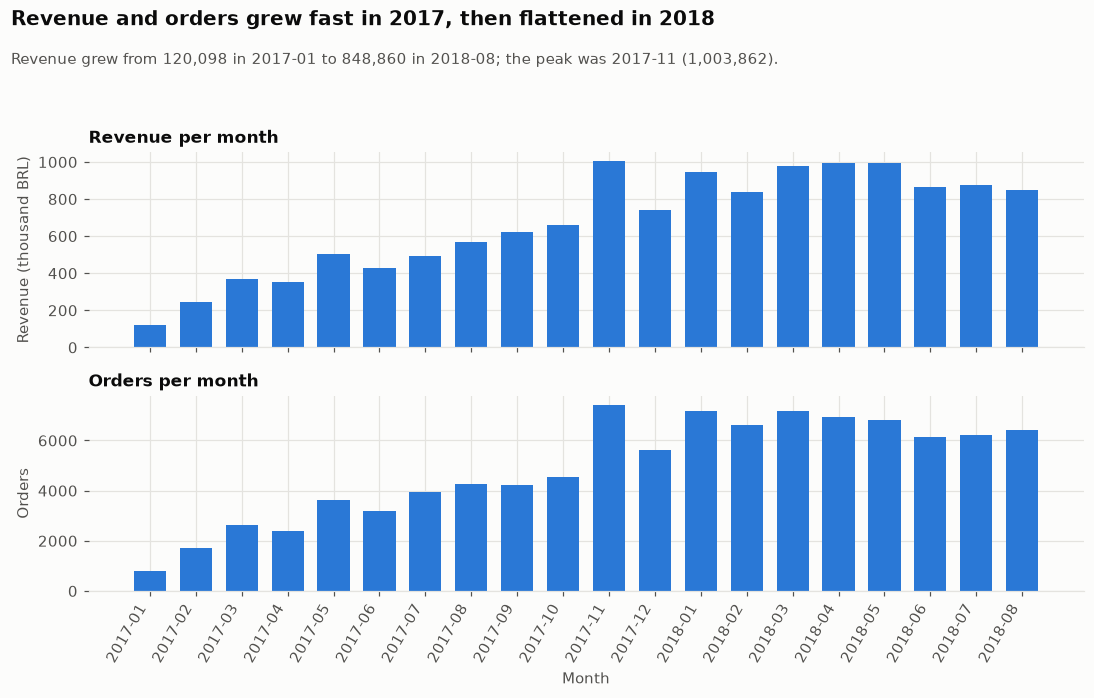

**Takeaway:** Revenue grew from 120,098 in 2017-01 to 848,860 in 2018-08; the peak was 2017-11 (1,003,862).

In [2]:
q2 = q("q02")
m = q2[q2.in_analysis_period].reset_index(drop=True)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
axes[0].bar(m.year_month, m.revenue / 1000, color=plots.BLUE, width=0.7)
axes[0].set_title("Revenue per month")
axes[0].set_ylabel("Revenue (thousand BRL)")
axes[1].bar(m.year_month, m.orders, color=plots.BLUE, width=0.7)
axes[1].set_title("Orders per month")
axes[1].set_ylabel("Orders")
axes[1].set_xlabel("Month")
plt.setp(axes[1].get_xticklabels(), rotation=60, ha="right")

peak = m.loc[m.revenue.idxmax()]
first, last = m.iloc[0], m.iloc[-1]
takeaway = (f"Revenue grew from {money(first.revenue)} in {first.year_month} to {money(last.revenue)} in {last.year_month}; "
            f"the peak was {peak.year_month} ({money(peak.revenue)}).")
plots.finish(fig, "Revenue and orders grew fast in 2017, then flattened in 2018", takeaway, "eda_01_monthly_revenue_orders.png")
say("**Takeaway:** " + takeaway)

## 2. When do customers buy? Weekday and hour (Q5)

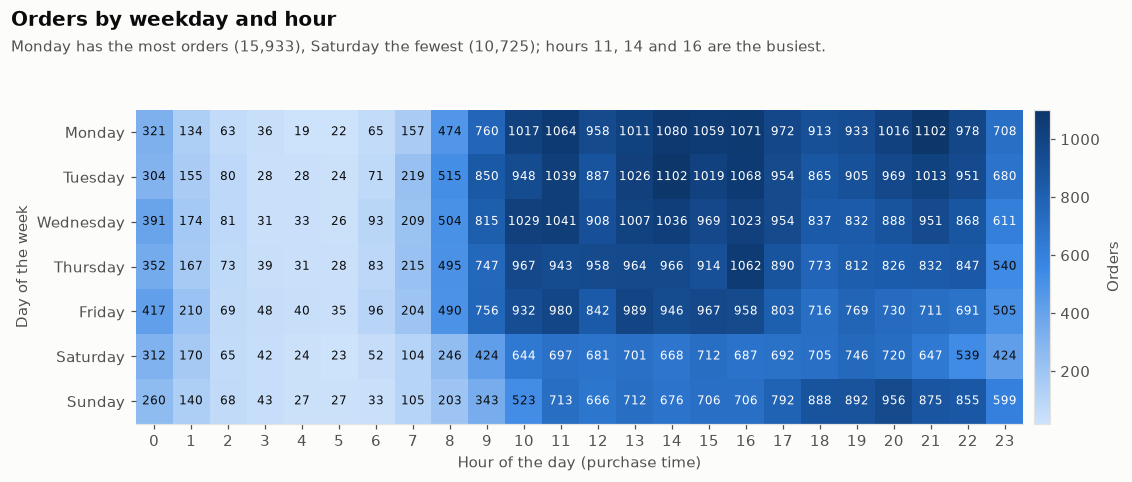

**Takeaway:** Monday has the most orders (15,933), Saturday the fewest (10,725); hours 11, 14 and 16 are the busiest.

In [3]:
q5 = q("q05")
grid = q5.pivot(index="day_name", columns="hour_of_day", values="orders")
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
grid = grid.loc[days]

fig, ax = plt.subplots(figsize=(11, 4.4))
im = ax.imshow(grid.values, cmap=plots.SEQ, aspect="auto")
ax.set_xticks(range(24), [str(h) for h in grid.columns])
ax.set_yticks(range(7), days)
ax.grid(False)
ax.set_xlabel("Hour of the day (purchase time)")
ax.set_ylabel("Day of the week")
plots.annotate_heatmap(ax, grid.values, fmt="{:.0f}")
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Orders")

by_day = q5.groupby("day_name").orders.sum()
by_hour = q5.groupby("hour_of_day").orders.sum()
top_hours = by_hour.sort_values(ascending=False).head(3).index.sort_values().tolist()
takeaway = (f"{by_day.idxmax()} has the most orders ({by_day.max():,}), {by_day.idxmin()} the fewest ({by_day.min():,}); "
            f"hours {top_hours[0]}, {top_hours[1]} and {top_hours[2]} are the busiest.")
plots.finish(fig, "Orders by weekday and hour", takeaway, "eda_02_weekday_hour_heatmap.png")
say("**Takeaway:** " + takeaway)

## 3. Category revenue: Pareto (Q7)

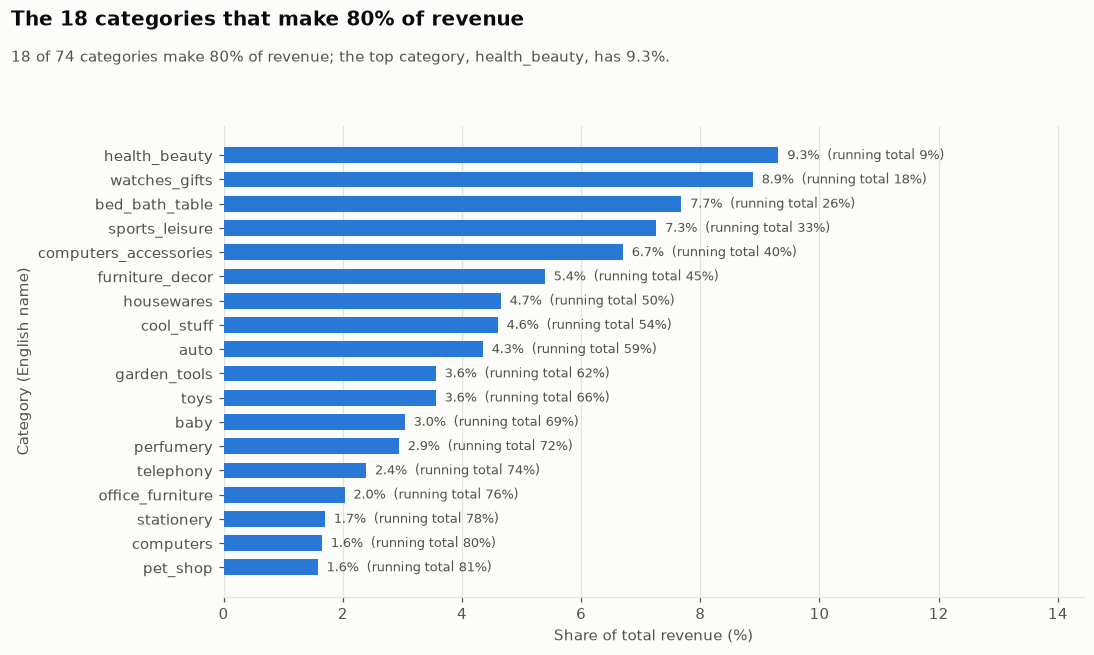

**Takeaway:** 18 of 74 categories make 80% of revenue; the top category, health_beauty, has 9.3%. Products with no category ('unknown') have 1.32% of revenue.

In [4]:
q7 = q("q07")
top = q7[q7.in_top_80pct].iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.category_en, top.revenue_share_pct, color=plots.BLUE, height=0.65)
ax.set_xlabel("Share of total revenue (%)")
ax.set_ylabel("Category (English name)")
ax.grid(axis="y", visible=False)
for y, (_, r) in enumerate(top.iterrows()):
    ax.text(r.revenue_share_pct + 0.15, y, f"{r.revenue_share_pct:.1f}%  (running total {r.cumulative_share_pct:.0f}%)",
            va="center", fontsize=8.5, color=plots.INK_2)
ax.set_xlim(0, top.revenue_share_pct.max() * 1.55)

n_top, n_all = int(q7.in_top_80pct.sum()), len(q7)
unknown = q7[q7.category_en == "unknown"].iloc[0]
takeaway = (f"{n_top} of {n_all} categories make 80% of revenue; the top category, {q7.category_en.iloc[0]}, "
            f"has {q7.revenue_share_pct.iloc[0]:.1f}%.")
plots.finish(fig, f"The {n_top} categories that make 80% of revenue", takeaway, "eda_03_category_pareto.png")
say("**Takeaway:** " + takeaway + f" Products with no category ('unknown') have {unknown.revenue_share_pct:.2f}% of revenue.")

## 4. New vs repeat customers (Q9)

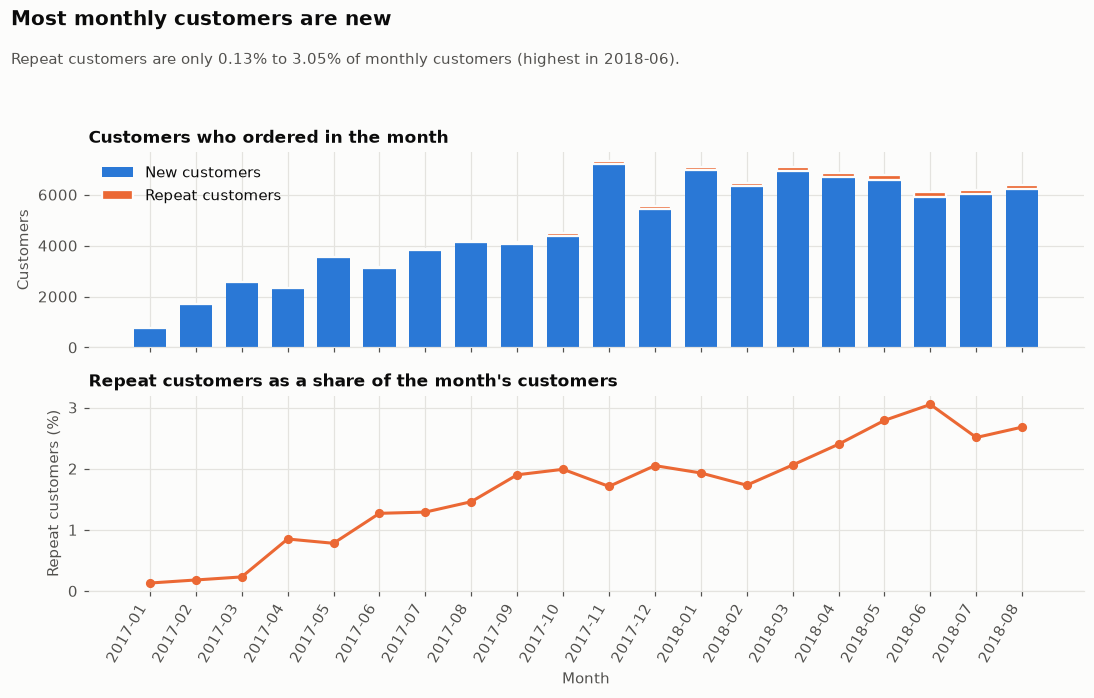

**Takeaway:** Repeat customers are only 0.13% to 3.05% of monthly customers (highest in 2018-06). Overall, 2,887 of 94,983 customers (3.04%) bought more than once (Q10).

In [5]:
q9 = q("q09")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
axes[0].bar(q9.year_month, q9.new_customers, color=plots.BLUE, width=0.7, label="New customers")
axes[0].bar(q9.year_month, q9.repeat_customers, bottom=q9.new_customers, color=plots.ORANGE, width=0.7,
            edgecolor=plots.SURFACE, linewidth=1.5, label="Repeat customers")
axes[0].set_title("Customers who ordered in the month")
axes[0].set_ylabel("Customers")
axes[0].legend(loc="upper left")
axes[1].plot(q9.year_month, q9.repeat_customer_pct, color=plots.ORANGE, linewidth=2, marker="o", markersize=5)
axes[1].set_title("Repeat customers as a share of the month's customers")
axes[1].set_ylabel("Repeat customers (%)")
axes[1].set_xlabel("Month")
axes[1].set_ylim(0, None)
plt.setp(axes[1].get_xticklabels(), rotation=60, ha="right")

hi = q9.loc[q9.repeat_customer_pct.idxmax()]
takeaway = (f"Repeat customers are only {q9.repeat_customer_pct.min():.2f}% to {q9.repeat_customer_pct.max():.2f}% of monthly "
            f"customers (highest in {hi.year_month}).")
plots.finish(fig, "Most monthly customers are new", takeaway, "eda_04_new_vs_repeat.png")
q10 = q("q10").set_index("metric").value
say("**Takeaway:** " + takeaway + f" Overall, {q10['repeat_customers']:,.0f} of {q10['customers']:,.0f} customers "
    f"({q10['repeat_purchase_rate_pct']:.2f}%) bought more than once (Q10).")

## 5. Cohort retention (Q11)

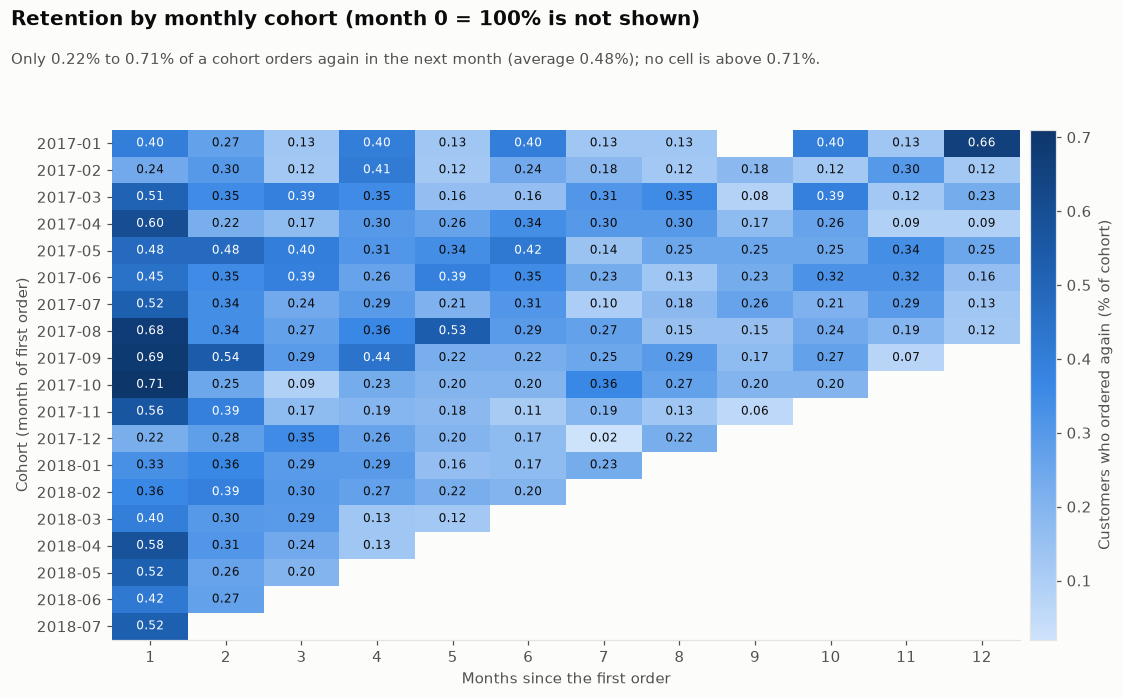

**Takeaway:** Only 0.22% to 0.71% of a cohort orders again in the next month (average 0.48%); no cell is above 0.71%.

In [6]:
q11 = q("q11")
piv = q11[q11.month_index >= 1].pivot(index="cohort_month", columns="month_index", values="retention_pct")

fig, ax = plt.subplots(figsize=(11, 6.4))
im = ax.imshow(piv.values, cmap=plots.SEQ, aspect="auto")
ax.set_xticks(range(piv.shape[1]), piv.columns)
ax.set_yticks(range(piv.shape[0]), piv.index)
ax.grid(False)
ax.set_xlabel("Months since the first order")
ax.set_ylabel("Cohort (month of first order)")
plots.annotate_heatmap(ax, piv.values, fmt="{:.2f}")
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Customers who ordered again (% of cohort)")

m1 = piv[1].dropna()
takeaway = (f"Only {m1.min():.2f}% to {m1.max():.2f}% of a cohort orders again in the next month "
            f"(average {m1.mean():.2f}%); no cell is above {np.nanmax(piv.values):.2f}%.")
plots.finish(fig, "Retention by monthly cohort (month 0 = 100% is not shown)", takeaway, "eda_05_cohort_retention.png")
say("**Takeaway:** " + takeaway)

## 6. Delivery delay vs review score (Q14)

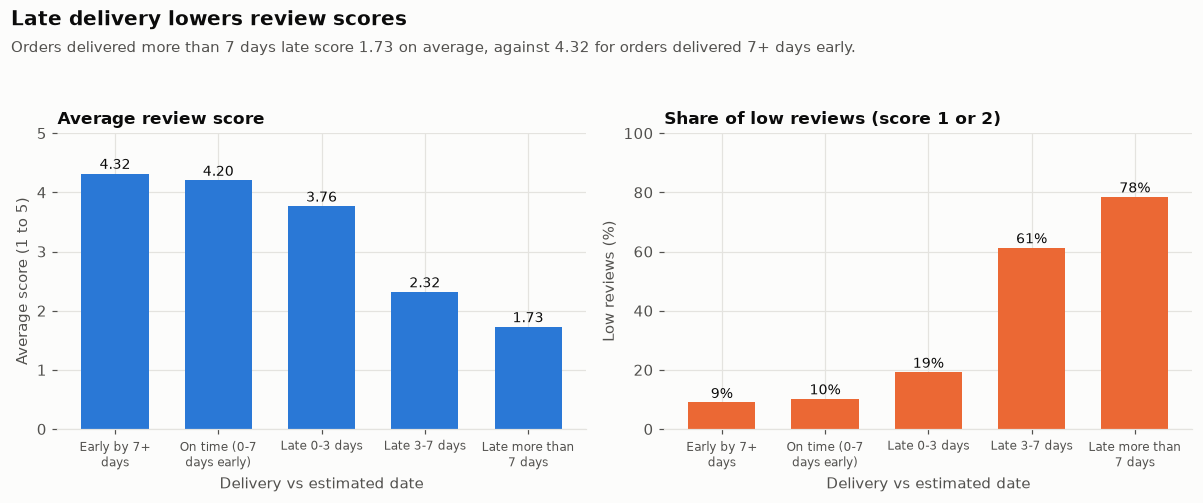

**Takeaway:** Orders delivered more than 7 days late score 1.73 on average, against 4.32 for orders delivered 7+ days early. Low reviews: 54.11% of late orders vs 9.22% of on-time orders.

In [7]:
q14 = q("q14")
b = q14[q14.level == "bucket"].sort_values("bucket_order")
labels = [textwrap.fill(g, 14) for g in b.group_name]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].bar(labels, b.avg_review_score, color=plots.BLUE, width=0.65)
axes[0].set_title("Average review score")
axes[0].set_ylabel("Average score (1 to 5)")
axes[0].set_ylim(0, 5)
axes[1].bar(labels, b.low_score_pct, color=plots.ORANGE, width=0.65)
axes[1].set_title("Share of low reviews (score 1 or 2)")
axes[1].set_ylabel("Low reviews (%)")
axes[1].set_ylim(0, 100)
for ax, col, fmt in [(axes[0], "avg_review_score", "{:.2f}"), (axes[1], "low_score_pct", "{:.0f}%")]:
    for x, v in enumerate(b[col]):
        ax.text(x, v + (0.08 if col == "avg_review_score" else 1.5), fmt.format(v), ha="center", fontsize=9, color=plots.INK)
    ax.set_xlabel("Delivery vs estimated date")
    ax.tick_params(axis="x", labelsize=8)

on, late = b.iloc[0], b.iloc[-1]
takeaway = (f"Orders delivered more than 7 days late score {late.avg_review_score:.2f} on average, "
            f"against {on.avg_review_score:.2f} for orders delivered 7+ days early.")
plots.finish(fig, "Late delivery lowers review scores", takeaway, "eda_06_delivery_vs_review.png")
lv = q14[q14.level == "late_vs_on_time"].set_index("group_name")
say("**Takeaway:** " + takeaway + f" Low reviews: {lv.loc['Late', 'low_score_pct']:.2f}% of late orders vs "
    f"{lv.loc['On time or early', 'low_score_pct']:.2f}% of on-time orders.")

## 7. Revenue by state (Q15)

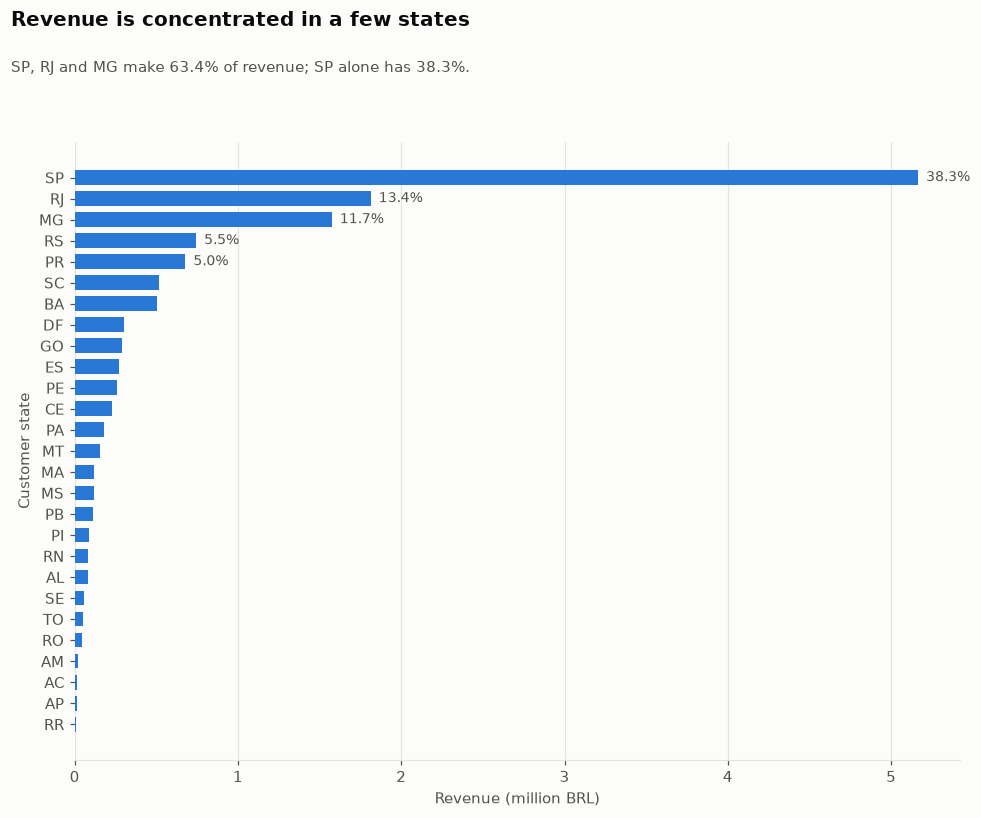

**Takeaway:** SP, RJ and MG make 63.4% of revenue; SP alone has 38.3%.

In [8]:
q15 = q("q15")
st = q15[q15.level == "State"].sort_values("revenue", ascending=True)
total = q15[q15.level == "All orders"].revenue.iloc[0]
st = st.assign(share=100 * st.revenue / total)

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(st.state, st.revenue / 1e6, color=plots.BLUE, height=0.7)
ax.set_xlabel("Revenue (million BRL)")
ax.set_ylabel("Customer state")
ax.grid(axis="y", visible=False)
for pos in range(len(st) - 5, len(st)):
    r = st.iloc[pos]
    ax.text(r.revenue / 1e6 + 0.05, pos, f"{r.share:.1f}%", va="center", fontsize=9, color=plots.INK_2)

top3 = st.tail(3).iloc[::-1]
takeaway = (f"{top3.state.iloc[0]}, {top3.state.iloc[1]} and {top3.state.iloc[2]} make {top3.share.sum():.1f}% of revenue; "
            f"{top3.state.iloc[0]} alone has {top3.share.iloc[0]:.1f}%.")
plots.finish(fig, "Revenue is concentrated in a few states", takeaway, "eda_07_revenue_by_state.png")
say("**Takeaway:** " + takeaway)

## 8. Key insights

In [9]:
q3 = q("q03").set_index("year_month")
g17 = q3.loc["2017-02":"2017-12", "mom_growth_pct"].mean()
g18 = q3.loc["2018-01":"2018-08", "mom_growth_pct"].mean()
h = q2[q2.in_analysis_period].set_index("year_month")
rev_17_11 = h.loc["2017-11", "revenue"]
avg_2018 = h.loc["2018-01":"2018-08", "revenue"].mean()
weekend_share = 100 * q5[q5.day_of_week >= 6].orders.sum() / q5.orders.sum()
share_peak = 100 * q5[q5.hour_of_day.between(10, 16)].orders.sum() / q5.orders.sum()
new_rev_share = 100 * q9.revenue_from_new.sum() / (q9.revenue_from_new.sum() + q9.revenue_from_repeat.sum())
late_n = lv.loc["Late", "orders"]
all_n = lv.orders.sum()

say(f'''
**Insight 1: Growth slowed in 2018.** The average month-over-month growth was {g17:.1f}% in 2017 (Feb to Dec)
and {g18:.1f}% in 2018 (Jan to Aug). The highest month was 2017-11 with {money(rev_17_11)} BRL
(likely a Black Friday effect); the average month in 2018 was {money(avg_2018)} BRL.
*Business meaning:* {new_rev_share:.1f}% of revenue comes from first-time buyers (Q9), so growth depends on winning new customers every month.

**Insight 2: Customers buy on weekdays and in the afternoon.** {weekend_share:.1f}% of orders are placed on Saturday or Sunday,
and {share_peak:.1f}% are placed between 10:00 and 16:59.
*Business meaning:* run promotions and have customer support online during working hours on weekdays.

**Insight 3: A few categories carry the business.** {n_top} of {n_all} categories make 80% of revenue,
and the top 3 categories ({', '.join(q7.category_en.head(3))}) make {q7.revenue_share_pct.head(3).sum():.1f}%.
*Business meaning:* focus stock, marketing and seller recruitment on these categories first.

**Insight 4: Almost nobody comes back.** Only {q10['repeat_purchase_rate_pct']:.2f}% of customers bought more than once,
and about {m1.mean():.2f}% of a cohort orders again in the next month.
*Business meaning:* growth depends on paid acquisition. A retention programme (e-mail, loyalty offers)
is the biggest open opportunity.

**Insight 5: Late delivery destroys reviews.** {lv.loc['Late', 'low_score_pct']:.1f}% of late orders get a low review (1 or 2),
against {lv.loc['On time or early', 'low_score_pct']:.1f}% of on-time orders. Late orders are {100 * late_n / all_n:.1f}% of delivered, reviewed orders.
*Business meaning:* cutting the number of late deliveries (better estimates, carrier control) protects review scores.

**Insight 6: Revenue is concentrated in the Southeast.** {top3.state.iloc[0]}, {top3.state.iloc[1]} and {top3.state.iloc[2]}
make {top3.share.sum():.1f}% of revenue.
*Business meaning:* the other regions are small markets today. Check delivery times there before spending on marketing.
''')


**Insight 1: Growth slowed in 2018.** The average month-over-month growth was 22.7% in 2017 (Feb to Dec)
and 2.5% in 2018 (Jan to Aug). The highest month was 2017-11 with 1,003,862 BRL
(likely a Black Friday effect); the average month in 2018 was 917,630 BRL.
*Business meaning:* 98.2% of revenue comes from first-time buyers (Q9), so growth depends on winning new customers every month.

**Insight 2: Customers buy on weekdays and in the afternoon.** 23.0% of orders are placed on Saturday or Sunday,
and 45.2% are placed between 10:00 and 16:59.
*Business meaning:* run promotions and have customer support online during working hours on weekdays.

**Insight 3: A few categories carry the business.** 18 of 74 categories make 80% of revenue,
and the top 3 categories (health_beauty, watches_gifts, bed_bath_table) make 25.9%.
*Business meaning:* focus stock, marketing and seller recruitment on these categories first.

**Insight 4: Almost nobody comes back.** Only 3.04% of customers bought more than once,
and about 0.48% of a cohort orders again in the next month.
*Business meaning:* growth depends on paid acquisition. A retention programme (e-mail, loyalty offers)
is the biggest open opportunity.

**Insight 5: Late delivery destroys reviews.** 54.1% of late orders get a low review (1 or 2),
against 9.2% of on-time orders. Late orders are 8.0% of delivered, reviewed orders.
*Business meaning:* cutting the number of late deliveries (better estimates, carrier control) protects review scores.

**Insight 6: Revenue is concentrated in the Southeast.** SP, RJ and MG
make 63.4% of revenue.
*Business meaning:* the other regions are small markets today. Check delivery times there before spending on marketing.


**Note on causes.** This analysis shows patterns, not proof of cause. For example, late delivery and low reviews move together,
but other things (product quality, price) may also play a part. The statistics notebook tests the delivery difference.

## 9. Save the key results for the report

In [10]:
import json

all_orders = q15[q15.level == "All orders"].iloc[0]
eda = {
    "source": "notebooks/02_eda.ipynb (reads sql/outputs)",
    "revenue_total": float(q2.revenue.sum()), "orders_total": int(q2.orders.sum()),
    "aov_all_orders": float(all_orders.avg_order_value),
    "customers_with_valid_order": int(q10["customers"]), "repeat_customers": int(q10["repeat_customers"]),
    "repeat_purchase_rate_pct": float(q10["repeat_purchase_rate_pct"]),
    "first_full_month": {"month": str(first.year_month), "revenue": float(first.revenue)},
    "last_full_month": {"month": str(last.year_month), "revenue": float(last.revenue)},
    "peak_month": {"month": str(peak.year_month), "revenue": float(peak.revenue)},
    "avg_mom_growth_2017_pct": float(g17), "avg_mom_growth_2018_pct": float(g18),
    "avg_revenue_2018_months": float(avg_2018),
    "weekend_order_share_pct": float(weekend_share), "orders_10_to_16h_share_pct": float(share_peak),
    "busiest_weekday": str(by_day.idxmax()), "quietest_weekday": str(by_day.idxmin()),
    "categories_total": int(n_all), "categories_for_80pct": int(n_top),
    "top3_categories": list(q7.category_en.head(3)), "top3_categories_share_pct": float(q7.revenue_share_pct.head(3).sum()),
    "unknown_category_revenue_share_pct": float(unknown.revenue_share_pct),
    "cohort_month1_retention_avg_pct": float(m1.mean()), "cohort_month1_retention_min_pct": float(m1.min()),
    "cohort_month1_retention_max_pct": float(m1.max()),
    "new_customer_revenue_share_pct": float(new_rev_share),
    "late_orders": int(lv.loc["Late", "orders"]), "on_time_orders": int(lv.loc["On time or early", "orders"]),
    "late_share_of_delivered_reviewed_pct": float(100 * late_n / all_n),
    "low_review_pct_late": float(lv.loc["Late", "low_score_pct"]),
    "low_review_pct_on_time": float(lv.loc["On time or early", "low_score_pct"]),
    "avg_score_late": float(lv.loc["Late", "avg_review_score"]),
    "avg_score_on_time": float(lv.loc["On time or early", "avg_review_score"]),
    "top3_states": list(top3.state), "top3_states_share_pct": float(top3.share.sum()),
    "top_state_share_pct": float(top3.share.iloc[0]),
}
(ROOT / "reports").mkdir(exist_ok=True)
(ROOT / "reports" / "eda_results.json").write_text(json.dumps(eda, indent=2), encoding="utf-8")
print("saved reports/eda_results.json with", len(eda), "values")

saved reports/eda_results.json with 36 values
